The standard procedure for any data science project:
1. Missing value imputation 
2. EDA
3. Feature selection + feature engineering 
4. Column transformation 
5. Model selection + tuning

In the titanic dataset, the columns were not that much. so the we could skip the eda and feature selection part. but in the housing price dataset. there are about 80 columns. So we have to do eda and feature selection. 

the houseprice dataset differs from the titanci in 2 ways.
1. It is a regression problem, and titanic's was a classification problem.
2. It has far more columns that the titanic. So we have to do feature selection here.

In [1]:
# standard imports
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

pd.set_option("display.max_columns",None)
# this part tells pandas to display all the columns in a dataset. instead of skipping columns by viewing ...

In [2]:
# Again standard train set and test set creation 
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

Now we need to understand the train and test set. So we will explore them a bit.

In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,6,1998,1998,Gable,CompShg,VinylSd,VinylSd,BrkFace,20.0,TA,TA,PConc,TA,TA,No,GLQ,602.0,Unf,0.0,324.0,926.0,GasA,Ex,Y,SBrkr,926,678,0,1604,0.0,0.0,2,1,3,1,Gd,7,Typ,1,Gd,Attchd,1998.0,Fin,2.0,470.0,TA,TA,Y,360,36,0,0,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,Inside,Gtl,StoneBr,Norm,Norm,TwnhsE,1Story,8,5,1992,1992,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,263.0,Unf,0.0,1017.0,1280.0,GasA,Ex,Y,SBrkr,1280,0,0,1280,0.0,0.0,2,0,2,1,Gd,5,Typ,0,NaN,Attchd,1992.0,RFn,2.0,506.0,TA,TA,Y,0,82,0,0,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [5]:
train.shape, test.shape

((1460, 81), (1459, 80))

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:
train.describe(include="O")

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,588,1460,1460,1460,1423,1423,1422,1423,1422,1460,1460,1460,1459,1460,1460,770,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,8,5,8,6,8,15,16,3,4,5,6,4,4,4,6,6,6,5,2,5,4,7,5,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,TA,TA,PConc,TA,TA,No,Unf,Unf,GasA,Ex,Y,SBrkr,TA,Typ,Gd,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,1141,1434,515,504,445,906,1282,647,649,1311,953,430,1256,1428,741,1365,1334,735,1360,380,870,605,1311,1326,1340,3,157,49,1267,1198


In [9]:
len(test.columns)

80

In [10]:
len(train.columns)

81

As we know the train set will have extra one column that the test set will predict. The "Target Variable".

I want to check which extra column(the target column) train has that the test does not.
In the titanic we could have found the target column easily just by glancing at the dataset. But here there are 80 columns. So finding the target column is not manually doable. So we have to write the following code.

In [11]:
target_col= list(set(train.columns)-set(test.columns))[0]
target_col
# here we take the list of column names of train and test and convert them into a set. Then we do set difference. only the target column will be in the
# training set and not the testing set. The code gives that as an output. 

'SalePrice'

Now we want to know about the target column.

In [12]:
train[target_col].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [13]:
train[target_col].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1460 entries, 0 to 1459
Series name: SalePrice
Non-Null Count  Dtype
--------------  -----
1460 non-null   int64
dtypes: int64(1)
memory usage: 11.5 KB


In [14]:
train[target_col].skew()

np.float64(1.8828757597682129)

Which means that our target column is rigthly skewed.

<Axes: xlabel='SalePrice', ylabel='Count'>

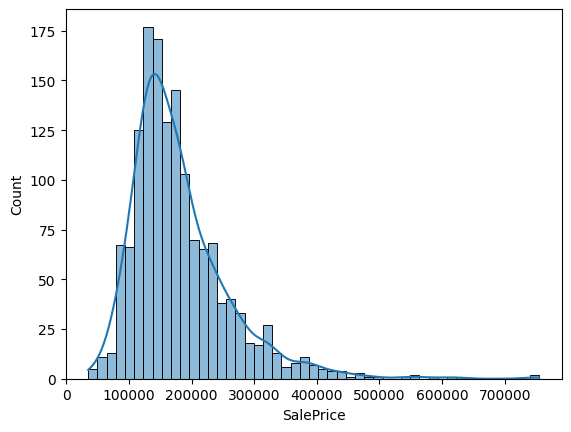

In [15]:
sns.histplot(train[target_col],kde = True)

From the histogram we can see that the saleprice column is rightly skewd

The evaluation of this cometetion is doen in RMSE (Root Mean Squared Error) of the log of the saleprice column. So we need to see the log of saleprice.

<Axes: xlabel='SalePrice', ylabel='Count'>

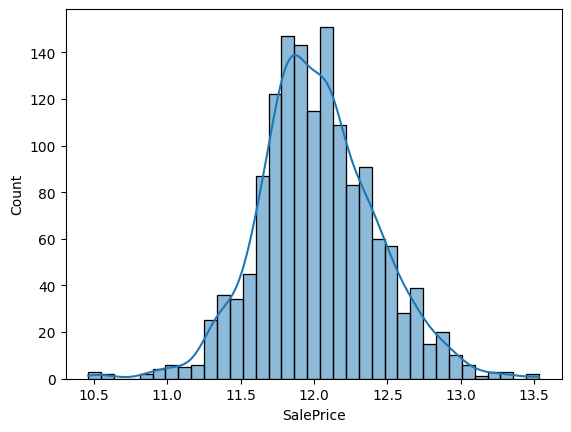

In [16]:
sns.histplot(np.log1p(train[target_col]),kde=True)
# log1p is basically log(1+value). It is used where the value that we want to log can be 0. 
# Here is the saleprice column the value is unlikely to be 0, but for safety measures we use log1p here. 

From the log of saleprice column, we can see it is fairly normal. Whats the significance of it being normal?
1. Linear models(Linear Regression, Ridge, and Lasso) assume normally distributed (or at least symmetric) residuals.
2. It reduces the influence of extreme outliers on the loss function

<Axes: xlabel='SalePrice', ylabel='Count'>

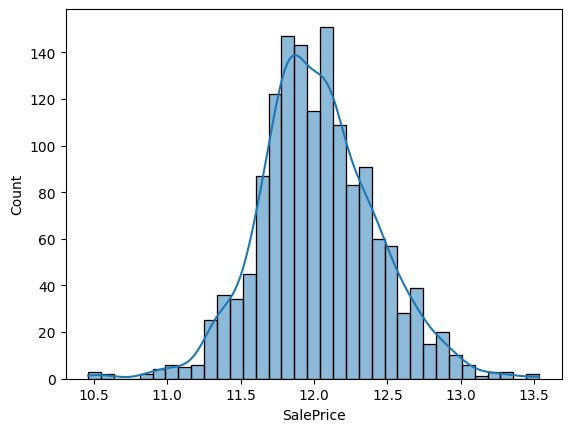

In [17]:
sns.histplot(np.log(train[target_col]),kde=True)

As we see, the log of the value gives the same graph.

# Handling Missing Values

Before we can do anything (feature selection or feature engineering), we have to first handle missing values.
We directly used columntransformer and imputer in the titanic because there were not many columns, so explicit feature selection was not needed. But in this dataset we need to select relevant features. For that we need to do EDA (on the training set). And that would be easier if we do not have any missing values in the training set. but we have to clean out the data in both the train and test sets. and for the training set in this one we have to manually fill the columns using fillna() function. 

In this dataset, missing values are a big problem. some missing values indicate genuine missing values (where the data is missing). but in other case the missing value (nan) means the category of "absence". suppose in garage variables nan means the absence of garage, not that the that particular variable is missing. In this case we cannot just use simple imputer, we need to fill those missing values as a category using .fillna() function.

Overall in any real data, the data is messy with missing values and errors which need to be corrected.

We will be filling both the train and test dataset NAN values with "None" in the case of absence of category. And we will fill the genuine missing values only in the train dataset for analysing the features further.

In [18]:
# I only want to see the columns which has missing values
train.isna().sum()[lambda x: x>0]
# the train.isna().sum() gives the list of the columns of train df with their missing values. And [lambda x: x>0] filters it with the x>0 condition. 

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [19]:
test.isna().sum()[lambda x: x>0]

MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtQual          44
BsmtCond          45
BsmtExposure      44
BsmtFinType1      42
BsmtFinSF1         1
BsmtFinType2      42
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
GarageType        76
GarageYrBlt       78
GarageFinish      78
GarageCars         1
GarageArea         1
GarageQual        78
GarageCond        78
PoolQC          1456
Fence           1169
MiscFeature     1408
SaleType           1
dtype: int64

1. Genuine missing values in TRAIN

    'LotFrontage',

    'MasVnrArea',
    'Electrical'


2. Missing values that represent a category in TRAIN (absence)

    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'MasVnrType',
    'FireplaceQu',
    'GarageYrBlt',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'BsmtExposure',
    'BsmtFinType2',
    'BsmtQual',
    'BsmtCond',
    'BsmtFinType1'


3. Genuine missing values in TEST

    'LotFrontage',
    'MasVnrArea',
    'MSZoning',
    'Functional',
    'BsmtFullBath',
    'Utilities',
    'BsmtHalfBath',
    'Exterior1st',
    'Exterior2nd',
    'TotalBsmtSF',
    'BsmtUnfSF',
    'BsmtFinSF2',
    'BsmtFinSF1',
    'KitchenQual',
    'GarageArea',
    'GarageCars',
    'SaleType'


4. Missing values that represent a category in TEST (absence)

    'PoolQC',
    'MiscFeature',
    'Alley',
    'Fence',
    'MasVnrType',
    'FireplaceQu',
    'GarageQual',
    'GarageCond',
    'GarageYrBlt',
    'GarageFinish',
    'GarageType',
    'BsmtCond',
    'BsmtQual',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2'


This is the general list which categories in train and test are representing genuine value missing and which are representing missing values as the absence of that feature. 

In the missing values some garage features and basement features represent the missing of garages and basements entirely. So we should check on them.

In [20]:
train[['GarageType','GarageFinish','GarageQual','GarageCond']].isna().sum()

GarageType      81
GarageFinish    81
GarageQual      81
GarageCond      81
dtype: int64

In [21]:
test[['GarageType','GarageFinish','GarageQual','GarageCond']].isna().sum()

GarageType      76
GarageFinish    78
GarageQual      78
GarageCond      78
dtype: int64

Here we see a mismatch in garage type and the other garage features. If other garage feature missing indicates the absence of a garage, then the garagetype should also be missing.

In [22]:
test[test["GarageType"].notnull() & test["GarageQual"].isna()]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
666,2127,60,RM,57.0,8094,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Norm,Norm,2fmCon,2.5Unf,6,8,1910,1983,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,PConc,TA,TA,Mn,Rec,196.0,Unf,0.0,1046.0,1242.0,GasA,Gd,Y,SBrkr,1242,742,0,1984,0.0,0.0,2,0,5,1,TA,8,Typ,0,NaN,Detchd,NaN,NaN,1.0,360.0,NaN,NaN,Y,64,0,180,0,0,0,NaN,MnPrv,Shed,1000,9,2008,WD,Normal
1116,2577,70,RM,50.0,9060,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,2Story,5,6,1923,1999,Gable,CompShg,Wd Sdng,Plywood,NaN,0.0,TA,TA,BrkTil,Gd,TA,No,ALQ,548.0,Unf,0.0,311.0,859.0,GasA,Ex,Y,SBrkr,942,886,0,1828,0.0,0.0,2,0,3,1,Gd,6,Typ,0,NaN,Detchd,NaN,NaN,NaN,NaN,NaN,NaN,Y,174,0,212,0,0,0,NaN,MnPrv,NaN,0,3,2007,WD,Alloca


This output shows all the 81 columns. But our main focus is on the garage columns. So we just need to focus on them.

In [23]:
mask = test["GarageType"].notnull() & test["GarageQual"].isnull()

a = test.loc[mask, ["GarageYrBlt",'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',"GarageCars","GarageArea"]]

In [24]:
a

,GarageYrBlt,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,NaN,Detchd,NaN,NaN,NaN,1.0,360.0
1116,NaN,Detchd,NaN,NaN,NaN,NaN,NaN


this is a problem. here row 1116 has an input error so the column GarageType has been inputted Detchd where it should have been NaN. and in the 666 row, there is a garage in that house (evident by the values in GarageCars and GarageArea) but the other garage values are NaN. So for row 1116 we can just change the GarageType to Nan. and for row 1116 house, we have to impute the missing values here.

when imputing, the more accurate imputation would be when we impute only considering the households that have a garage in them.

In [25]:
test.loc[1116,"GarageType"]= np.nan
# here we just fill the 1116 rows garagetype with nan, as there is no garage in that house. 

In [26]:
test.loc[1116,"GarageType"]
# checking if the code worked. 

nan

Now we need to impute median (for numeric columns) and mode (for categorical columns) for the row 666.

In [27]:
median_impute = ["GarageYrBlt"]
mode_impute = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',"GarageCars"]

In [28]:
# Calculate medians first for the numeric rows 
medians = test[median_impute].median()

# Fill and explicitly opt-in to the type conversion
test.loc[666, median_impute] = test.loc[666, median_impute].fillna(medians).infer_objects(copy=False)

C:\Users\Raiyan\AppData\Local\Temp\ipykernel_15500\570206656.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test.loc[666, median_impute] = test.loc[666, median_impute].fillna(medians).infer_objects(copy=False)


In [29]:
# 1. Calculate the mode, but grab ONLY the first row (.iloc[0]) to get a single value per column
modes = test[mode_impute].mode().iloc[0]

# 2. Fill the missing values for row 1116
test.loc[666, mode_impute] = test.loc[666, mode_impute].fillna(modes)

In [30]:
test.loc[[666,1116],["GarageYrBlt",'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',"GarageCars","GarageArea"]]
# checking whether the two rows have been fixed. 

,GarageYrBlt,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,1979.0,Detchd,Unf,TA,TA,1.0,360.0
1116,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Now we will be filling the missing values in both train and test set.

In [31]:
train[["GarageArea","GarageCars"]]= train[["GarageArea","GarageCars"]].fillna(0)
train[['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']]= train[['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']].fillna("None")

The garageyrblt is an interesting case. Here Garageyearbuilt is a time column. so we should not put 0 as a value of this column because that would imply the garage has been built in the year 0 which will be a problem when we train ml models. So what to do?

Garage is a part of the house. And as we cannot know when the garage was built, so we can use the year the house was built as a replacement for it. As the two columns are related, this approach should work fine. 
Here the garageyearbuilt and yearbuilt are called sibling columns.

In [32]:
no_garage_train = train["GarageYrBlt"].isna()
train.loc[no_garage_train, "GarageYrBlt"] = train.loc[no_garage_train, "YearBuilt"]

We will do same for test.

In [33]:
test[["GarageArea","GarageCars"]]= test[["GarageArea","GarageCars"]].fillna(0)
test[['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']]= test[['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']].fillna("None")

In [34]:
no_garage_test = test["GarageYrBlt"].isna()
test.loc[no_garage_test, "GarageYrBlt"] = test.loc[no_garage_test, "YearBuilt"]

In [35]:
train.isna().sum()[lambda x: x>0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [36]:
test.isna().sum()[lambda x: x>0]

MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtQual          44
BsmtCond          45
BsmtExposure      44
BsmtFinType1      42
BsmtFinSF1         1
BsmtFinType2      42
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
PoolQC          1456
Fence           1169
MiscFeature     1408
SaleType           1
dtype: int64

Now we move to checking the basement columns.

In [37]:
basement_cat_cols = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
train[basement_cat_cols].isna().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    38
BsmtFinType1    37
BsmtFinType2    38
dtype: int64

There is obvious mismatch.
So we will use conditional to check the mismatch rows and solve them accordingly.

In [38]:
train[train["BsmtQual"].notnull() & train["BsmtExposure"].isnull()][basement_cat_cols]
# finds the rows where bsmtqual is not null and bsmtexposure is null and only shows the basement columns

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
948,Gd,TA,NaN,Unf,Unf


In [39]:
train[train["BsmtQual"].notnull() & train["BsmtFinType2"].isnull()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
332,Gd,TA,No,GLQ,NaN


here in this case the NaNs mean that the value is missing (as all the other rows have values, meaning the house indeed has a basement) and it is not a categorical (missing basement) feature. so we will need to impute it.

In [40]:
mode_basement_exp = train["BsmtExposure"].mode()[0]

In [41]:
mode_basement_exp

'No'

In [42]:
train.loc[948,"BsmtExposure"] = mode_basement_exp
# basically replaces the value of a particular row and column to the mode here. 

In [43]:
train.loc[948,basement_cat_cols]

BsmtQual         Gd
BsmtCond         TA
BsmtExposure     No
BsmtFinType1    Unf
BsmtFinType2    Unf
Name: 948, dtype: object

In [44]:
mode_fintype2 = train["BsmtFinType2"].mode()[0]

In [45]:
train.loc[332,"BsmtFinType2"] = mode_fintype2

In [46]:
train.loc[332,basement_cat_cols]

BsmtQual         Gd
BsmtCond         TA
BsmtExposure     No
BsmtFinType1    GLQ
BsmtFinType2    Unf
Name: 332, dtype: object

In [47]:
# checking if the train data basement columns have been fixed.
train[basement_cat_cols].isna().sum()

BsmtQual        37
BsmtCond        37
BsmtExposure    37
BsmtFinType1    37
BsmtFinType2    37
dtype: int64

Now we can fill the missing values for these columns.

In [48]:
train[basement_cat_cols]=train[basement_cat_cols].fillna("None")

In [49]:
train.isna().sum()[lambda x: x>0]

LotFrontage     259
Alley          1369
MasVnrType      872
MasVnrArea        8
Electrical        1
FireplaceQu     690
PoolQC         1453
Fence          1179
MiscFeature    1406
dtype: int64

Now we can move to the test dataset.

In [50]:
test[basement_cat_cols].isna().sum()

BsmtQual        44
BsmtCond        45
BsmtExposure    44
BsmtFinType1    42
BsmtFinType2    42
dtype: int64

Mismatch found.

In [51]:
test[test["BsmtCond"].isna() & test["BsmtQual"].notnull() & test["BsmtExposure"].notnull()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
580,Gd,NaN,Mn,GLQ,Rec
725,TA,NaN,No,BLQ,Unf
1064,TA,NaN,Av,ALQ,Unf


Leakage happens specifically when information from test influences what the model learns from train. But here we will use test's own mode to impute test's data. In titanic we used train set's statistics to impute test set data. That is not a problem. And here we will use test set statistic to impute test set data. That is also not a problem. The problem will be when we will use test set statistic to impute train set data.

In [52]:
test.loc[[580,725,1064],"BsmtCond"] = test["BsmtCond"].mode()[0]

In [53]:
test[test["BsmtCond"].isna() & test["BsmtQual"].notnull() & test["BsmtExposure"].notnull()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2


In [54]:
test[basement_cat_cols].isna().sum()

BsmtQual        44
BsmtCond        42
BsmtExposure    44
BsmtFinType1    42
BsmtFinType2    42
dtype: int64

In [55]:
test[test["BsmtCond"].notna() & test["BsmtQual"].isna()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
757,NaN,Fa,No,Unf,Unf
758,NaN,TA,No,Unf,Unf


In [56]:
test.loc[[757,758],"BsmtQual"] = test["BsmtQual"].mode()[0]

In [57]:
test[test["BsmtCond"].notna() & test["BsmtQual"].isna()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2


In [58]:
test[test["BsmtCond"].notna() & test["BsmtExposure"].isna()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
27,Gd,TA,NaN,Unf,Unf
888,Gd,TA,NaN,Unf,Unf


In [59]:
test.loc[[27,888],"BsmtExposure"] = test["BsmtExposure"].mode()[0]

In [60]:
test[test["BsmtCond"].notna() & test["BsmtExposure"].isna()][basement_cat_cols]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2


In [61]:
test[basement_cat_cols].isna().sum()

BsmtQual        42
BsmtCond        42
BsmtExposure    42
BsmtFinType1    42
BsmtFinType2    42
dtype: int64

The basement cols of test set has been fixed. now we can fill in the missing values.

In [62]:
test["BsmtFinType1"] = test["BsmtFinType1"].fillna("None")

In [63]:
test[['BsmtQual', 'BsmtCond', 'BsmtExposure',"BsmtFinType2"]]= test[['BsmtQual', 'BsmtCond', 'BsmtExposure',"BsmtFinType2"]].fillna("None")

In [64]:
test[basement_cat_cols].isna().sum()
# checking if the code worked. 

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

In [65]:
print(f"train :\n\n{train.isna().sum()[lambda x: x>0]}\n")
print(f"test :\n\n{test.isna().sum()[lambda x: x>0]}\n")

train :

LotFrontage     259
Alley          1369
MasVnrType      872
MasVnrArea        8
Electrical        1
FireplaceQu     690
PoolQC         1453
Fence          1179
MiscFeature    1406
dtype: int64

test :

MSZoning           4
LotFrontage      227
Alley           1352
Utilities          2
Exterior1st        1
Exterior2nd        1
MasVnrType       894
MasVnrArea        15
BsmtFinSF1         1
BsmtFinSF2         1
BsmtUnfSF          1
TotalBsmtSF        1
BsmtFullBath       2
BsmtHalfBath       2
KitchenQual        1
Functional         2
FireplaceQu      730
PoolQC          1456
Fence           1169
MiscFeature     1408
SaleType           1
dtype: int64



test dataset missing values still have some basement related features. so lets check on them.

In [66]:
bsmt = ["BsmtFinSF1","BsmtFinSF2","BsmtUnfSF","TotalBsmtSF","BsmtFullBath","BsmtHalfBath"]
all_bsmt_cols = list(set(bsmt) | set(basement_cat_cols))
test[test["BsmtFinSF1"].isnull() & test["BsmtUnfSF"].isnull()][all_bsmt_cols]


,BsmtCond,BsmtFinSF1,BsmtQual,BsmtExposure,BsmtFullBath,BsmtUnfSF,TotalBsmtSF,BsmtFinType1,BsmtFinSF2,BsmtHalfBath,BsmtFinType2
660,None,NaN,None,None,NaN,NaN,NaN,None,NaN,NaN,None


In [67]:
test.loc[660,bsmt] = 0

In [68]:
test[all_bsmt_cols].isna().sum()[lambda x: x>0]

BsmtFullBath    1
BsmtHalfBath    1
dtype: int64

In [69]:
test[test["BsmtFullBath"].isna() & test["BsmtHalfBath"].isna()][bsmt]

,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
728,0.0,0.0,0.0,0.0,NaN,NaN


In [70]:
test.loc[728,bsmt] = 0

To find the unique values of a column (which helps to determine whether the column is categorical or numeric easily) we use .unique() function. and to see the frequency table we use .value_counts().

In [71]:
test[all_bsmt_cols].isna().sum()[lambda x: x>0]

Series([], dtype: int64)

In [72]:
test.isna().sum()[lambda x: x>0]

MSZoning          4
LotFrontage     227
Alley          1352
Utilities         2
Exterior1st       1
Exterior2nd       1
MasVnrType      894
MasVnrArea       15
KitchenQual       1
Functional        2
FireplaceQu     730
PoolQC         1456
Fence          1169
MiscFeature    1408
SaleType          1
dtype: int64

The basement columns have been fixed.

In [73]:
train.isna().sum()[lambda x: x>0]

LotFrontage     259
Alley          1369
MasVnrType      872
MasVnrArea        8
Electrical        1
FireplaceQu     690
PoolQC         1453
Fence          1179
MiscFeature    1406
dtype: int64

Here masvnr has a missmatch. lets fix this

In [74]:
train[train["MasVnrType"].isna() & train["MasVnrArea"].notna()][["MasVnrType","MasVnrArea"]]

,MasVnrType,MasVnrArea
1,NaN,0.0
3,NaN,0.0
5,NaN,0.0
8,NaN,0.0
9,NaN,0.0
...,...,...
1454,NaN,0.0
1455,NaN,0.0
1457,NaN,0.0
1458,NaN,0.0


In [75]:
train[train["MasVnrType"].isna() & train["MasVnrArea"].isna()][["MasVnrType","MasVnrArea"]]

,MasVnrType,MasVnrArea
234,NaN,NaN
529,NaN,NaN
650,NaN,NaN
936,NaN,NaN
973,NaN,NaN
977,NaN,NaN
1243,NaN,NaN
1278,NaN,NaN


so massvnr area needs to be filled by 0.

In [76]:
train["MasVnrArea"] = train["MasVnrArea"].fillna(0)

In [77]:
train[train["MasVnrType"].isna() & train["MasVnrArea"].isna()][["MasVnrType","MasVnrArea"]]

,MasVnrType,MasVnrArea


In [78]:
train.isna().sum()[lambda x: x>0]

LotFrontage     259
Alley          1369
MasVnrType      872
Electrical        1
FireplaceQu     690
PoolQC         1453
Fence          1179
MiscFeature    1406
dtype: int64

For masvnrarea for test set

In [79]:
test.isna().sum()[lambda x: x>0]

MSZoning          4
LotFrontage     227
Alley          1352
Utilities         2
Exterior1st       1
Exterior2nd       1
MasVnrType      894
MasVnrArea       15
KitchenQual       1
Functional        2
FireplaceQu     730
PoolQC         1456
Fence          1169
MiscFeature    1408
SaleType          1
dtype: int64

In [80]:
test["MasVnrArea"] = test["MasVnrArea"].fillna(0) # as vnr area here will also be 0, not null :)

In [81]:
test.isna().sum()[lambda x: x>0]

MSZoning          4
LotFrontage     227
Alley          1352
Utilities         2
Exterior1st       1
Exterior2nd       1
MasVnrType      894
KitchenQual       1
Functional        2
FireplaceQu     730
PoolQC         1456
Fence          1169
MiscFeature    1408
SaleType          1
dtype: int64

we will handle masvnrtype as a anbsent categorical missing value and fix it with the other. 

Now the garage, basement and vnr area missing value problems have been fixed. Now we just need to sort out form the missing values which columns NA are genuine missing values and which column NAs represent absence of the feature.
using .unique() and .value_counts() function helps us with this

For training set:

LotFrontage  -> genuine missing 

Alley        -> absence (none)

MasVnrType   -> absence    (none)   

Electrical   -> geuine missing   

FireplaceQu  -> absence(none)

PoolQC       -> absence (none)

Fence        -> absence (none)

MiscFeature  -> absence (none)

Now lets fill the absent ones with none

In [82]:
absent_col = ["Alley","MasVnrType","FireplaceQu","PoolQC","Fence","MiscFeature"]
train[absent_col] = train[absent_col].fillna("None")

In [83]:
train.isna().sum()[lambda x: x>0]

LotFrontage    259
Electrical       1
dtype: int64

In [84]:
test.isna().sum()[lambda x: x>0]

MSZoning          4
LotFrontage     227
Alley          1352
Utilities         2
Exterior1st       1
Exterior2nd       1
MasVnrType      894
KitchenQual       1
Functional        2
FireplaceQu     730
PoolQC         1456
Fence          1169
MiscFeature    1408
SaleType          1
dtype: int64

For test dataset:
MSZoning        -> genuine missing

LotFrontage     -> genuine missing

Alley           -> absence (none)

Utilities       -> genuine missing

Exterior1st     -> genuine missing

Exterior2nd     -> genuine missing

MasVnrType      -> absense (none)

KitchenQual     -> genuine missing

Functional      -> genuine missing

FireplaceQu     -> absence (none)

PoolQC          -> absense (none)

Fence           -> absence (none)

MiscFeature     -> absense (none)

SaleType        -> genuine missing

Again lets fill up the absence columns with none

In [85]:
test_absence = ["Alley","MasVnrType","FireplaceQu","PoolQC","Fence","MiscFeature"]
test[test_absence] = test[test_absence].fillna("None")

In [86]:
test.isna().sum()[lambda x: x>0]

MSZoning         4
LotFrontage    227
Utilities        2
Exterior1st      1
Exterior2nd      1
KitchenQual      1
Functional       2
SaleType         1
dtype: int64

In [87]:
test["GarageYrBlt"].value_counts()

GarageYrBlt
2005.0    80
2007.0    67
2006.0    58
2004.0    48
2003.0    42
          ..
1902.0     1
1932.0     1
1905.0     1
2207.0     1
1943.0     1
Name: count, Length: 103, dtype: int64

in here we will see that there will be a garage built in the year 2207 :). which is certainly a mistake while inputting the data. But we will see in the future that we actually drop garageyrbuilt column entirely and work with yearbuilt col instead...so i will be lazy and do nothing :)

In [88]:
test["MSSubClass"].dtype

dtype('int64')

MSsubclass is actually categorical as it is representing types of dwelling....even though it is in int format. So we need to fix that

In [89]:
test["MSSubClass"] = test["MSSubClass"].astype("str")

In [90]:
test["MSSubClass"].dtype

dtype('O')

In [91]:
train["MSSubClass"].dtype

dtype('int64')

In [92]:
train["MSSubClass"] = train["MSSubClass"].astype("str")

In [93]:
train["MSSubClass"].dtype

dtype('O')

Now the problem with absent features in missing values is now finished. We can now move on to EDA, Feature selection and Feature engineering.

lets first split the train dataset the same way we did in titanic

In [94]:
X = train.drop(columns=target_col)
y = np.log1p(train[target_col])
# we need to fit model and calculate everything based on the logarithm of salesprice because the RMSE will be 
# calculated on the logarithm of salesprice
# after we do calculations , fit models and predict, we will run np.exp1() on the target var to convert it back to numeric data

In [95]:
X.shape,y.shape,train.shape

((1460, 80), (1460,), (1460, 81))

Now before we move to column transformation, we have a problem. There are simply too many features. we must first impute the remaining missing values in X(train), then do EDA to know which features are important to us, then do feature engineering. then we can safely move to column transformer that will take the columns that are relevant to us.

### firstly lets impute the remaining missing values in X

In [96]:
X.isna().sum()[lambda x: x>0]

LotFrontage    259
Electrical       1
dtype: int64

In [97]:
X["LotFrontage"] = X["LotFrontage"].fillna(X["LotFrontage"].median()) # as LotFrontage is numeric
X["Electrical"] = X["Electrical"].fillna(X["Electrical"].mode()[0]) # as Electrical is categorical

In [98]:
X.isna().sum()[lambda x: x>0]

Series([], dtype: int64)

The missing values have been computed. Now we can start with the EDA.

### EDA, Feature selection and Feature Engineering

First we need to see each column's correlation with the saleprice (target col). We can get an idea about which column to drop, which to merge and which columns may have Multicollinearity.

In [99]:
X.select_dtypes(include="number").corrwith(y).sort_values(key = abs, ascending = False)

OverallQual      0.817185
GrLivArea        0.700927
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF         0.596981
FullBath         0.594771
YearBuilt        0.586570
GarageYrBlt      0.568696
YearRemodAdd     0.565608
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
MasVnrArea       0.426776
BsmtFinSF1       0.372023
LotFrontage      0.335292
WoodDeckSF       0.334135
OpenPorchSF      0.321053
2ndFlrSF         0.319300
HalfBath         0.313982
LotArea          0.257320
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209043
EnclosedPorch   -0.149050
KitchenAbvGr    -0.147548
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057330
3SsnPorch        0.054900
LowQualFinSF    -0.037963
YrSold          -0.037263
OverallCond     -0.036868
MiscVal         -0.020021
Id              -0.017942
BsmtHalfBath    -0.005149
BsmtFinSF2       0.004832
dtype: float64

Multicollinearity is a statistical condition in regression analysis where two or more independent (predictor) variables are highly correlated with each other.
Here some columns correlation value can be largely explained by its sibling.
These kind of multicolinearity is bad for model training and prediction in linear regression.
some columns that contribute towards multicoliniarity are given below.

In [100]:
X["GarageCars"].corr(X["GarageArea"])

np.float64(0.8824754142814616)

In [101]:
X["TotalBsmtSF"].corr(X["1stFlrSF"])

np.float64(0.8195299750050336)

In [102]:
X["GarageYrBlt"].corr(X["YearBuilt"])

np.float64(0.8451406660104684)

solve for this multicolinearity can be done by:
1. droping one column
2. combining the multicolinear columns into one column
3. ignoring it, and keeping both columns

Here we will create a new column named "Total_sf" which will calculate the total square feet of basement, 1st floor and the 2nd floor.
And we will also drop the columns "GarageArea","GarageYrBlt","TotalBsmtSF","1stFlrSF","2ndFlrSF", "Id".

Id is not relevant to saleprice in anyway. 
"TotalBsmtSF","1stFlrSF","2ndFlrSF" are getting merged in total columns. which will reduce Multicollinearity.
GarageArea was correlated to garagecars. and as garagecars is more highly correlated to salesprice, we dropped the garagearea.
the garageyearbuilt is basically related to the year the house was built. so we can comfortably drop it and work with the yearblt col.

In [103]:
test_id = test["Id"]
for df in (X,test):
    
    df["Total_sf"] = df["TotalBsmtSF"]+df["1stFlrSF"]+df["2ndFlrSF"]
    df.drop(["GarageArea","GarageYrBlt","TotalBsmtSF","1stFlrSF","2ndFlrSF", "Id"], axis=1, inplace=True)

In [104]:
X["Total_sf"].corr(y)

np.float64(0.7772965628581221)

The total_sf is highly correlated to target col as expected. Now lets see the correlations for the new columns.

In [105]:
X.select_dtypes(include="number").corrwith(y).sort_values(key = abs, ascending = False)

OverallQual      0.817185
Total_sf         0.777297
GrLivArea        0.700927
GarageCars       0.680625
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
MasVnrArea       0.426776
BsmtFinSF1       0.372023
LotFrontage      0.335292
WoodDeckSF       0.334135
OpenPorchSF      0.321053
HalfBath         0.313982
LotArea          0.257320
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209043
EnclosedPorch   -0.149050
KitchenAbvGr    -0.147548
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057330
3SsnPorch        0.054900
LowQualFinSF    -0.037963
YrSold          -0.037263
OverallCond     -0.036868
MiscVal         -0.020021
BsmtHalfBath    -0.005149
BsmtFinSF2       0.004832
dtype: float64

We can see the correlation for the numeric columns. But for the categorical columns, we do not have correlations. We will be needing to do bucketing in the categorical columns.
bucketing categorical columns means grouping multiple categories into fewer, broader categories.
when doing onehotencoding of nominal columns, it would be a problem if too many columns of some rows are 0's. for this reason we do bucketing, so that the number of columns decrease.

In [106]:
X.columns, test.columns

(Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
        'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
        'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
        'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
        'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
        'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
        'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
        'BsmtFinSF2', 'BsmtUnfSF', 'Heating', 'HeatingQC', 'CentralAir',
        'Electrical', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath',
        'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr',
        'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces',
        'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageCars', 'GarageQual',
        'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF',
        'EnclosedPorch', '3SsnPorch'

Lets first see Neighborhood as an example.

In [107]:
y.groupby(X['Neighborhood']).mean().sort_values()

Neighborhood
IDOTRR     11.446901
MeadowV    11.474533
BrDale     11.547874
BrkSide    11.679736
OldTown    11.703873
Edwards    11.712321
Sawyer     11.811475
Blueste    11.826543
SWISU      11.838442
NPkVill    11.866484
NAmes      11.868052
Mitchel    11.933954
SawyerW    12.090695
NWAmes     12.130614
Gilbert    12.155809
CollgCr    12.163647
Blmngtn    12.169421
Crawfor    12.206664
ClearCr    12.239905
Somerst    12.296500
Veenker    12.344180
Timber     12.363460
StoneBr    12.585490
NridgHt    12.619415
NoRidge    12.676003
Name: SalePrice, dtype: float64

In [108]:
X["Neighborhood"].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

here some neighbourhoods have really low value counts. so we can just merge them in "others" category.
for the cutoff point, we will consider 15 to be the ideal cutoff point as it cutsoff the genuine tiny neighbourhoods.

In [109]:
rare_neighbourhoods = X["Neighborhood"].value_counts()[lambda x: x<15].index

In [110]:
X["Neighborhood"] = X["Neighborhood"].replace(rare_neighbourhoods, "Other")
test["Neighborhood"] = test["Neighborhood"].replace(rare_neighbourhoods, "Other")

In [111]:
X["Neighborhood"].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Other       22
MeadowV     17
Blmngtn     17
BrDale      16
Name: count, dtype: int64

In [112]:
set(test['Neighborhood'].unique()) - set(X['Neighborhood'].unique())

set()

In [113]:
nominal =["MSSubClass","MSZoning","Street","Alley","LandContour","LotConfig","Neighborhood","Condition1","Condition2",
         "HouseStyle","RoofStyle","RoofMatl","Exterior1st","Exterior2nd","MasVnrType","Foundation","Heating","Electrical",
         "GarageType","MiscFeature","SaleType","SaleCondition","BldgType"]
# unfortunately this listing of categorical columns has to be done manually :) 

What we did in the neighborhood column we cannot check for every nominal column manuslly. so we have to write some code.
we will only check this for nominal columns as ordinal column does not suffer from too many column 0 problem of onehotencoding.
we first need to identify the columns that have rare categories. 

In [114]:
extreme_cols = []
for col in nominal:
    print(col, X[col].value_counts().min())
    if X[col].value_counts().min() < 8:
        extreme_cols.append(col)

MSSubClass 4
MSZoning 10
Street 6
Alley 41
LandContour 36
LotConfig 4
Neighborhood 16
Condition1 2
Condition2 1
HouseStyle 8
RoofStyle 2
RoofMatl 1
Exterior1st 1
Exterior2nd 1
MasVnrType 15
Foundation 3
Heating 1
Electrical 1
GarageType 6
MiscFeature 1
SaleType 2
SaleCondition 4
BldgType 31


In [115]:
extreme_cols

['MSSubClass',
 'Street',
 'LotConfig',
 'Condition1',
 'Condition2',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'Foundation',
 'Heating',
 'Electrical',
 'GarageType',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

In [116]:
for col in extreme_cols:
    print(f"{X[col].value_counts()}\n")

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

Condition1
Norm      1260
Feedr       81
Artery      48
RRAn        26
PosN        19
RRAe        11
PosA         8
RRNn         5
RRNe         2
Name: count, dtype: int64

Condition2
Norm      1445
Feedr        6
Artery       2
RRNn         2
PosN         2
PosA         1
RRAn         1
RRAe         1
Name: count, dtype: int64

RoofStyle
Gable      1141
Hip         286
Flat         13
Gambrel      11
Mansard       7
Shed          2
Name: count, dtype: int64

RoofMatl
CompShg    1434
Tar&Grv      11
WdShngl       6
WdShake       5
Metal         1
Membran       1
Roll          1
ClyTile       1
Name: count, dtype:

We need to define a function so we dont have to manually replace the rare categories with "other" for every column that we want.

In [117]:
def bucket_rare_category(df_train, df_test, col,threshold):
    rare = df_train[col].value_counts()[lambda x: x<=threshold].index
    df_train[col] = df_train[col].replace(rare, "Other")
    df_test[col] = df_test[col].replace(rare, "Other")

In [118]:
bucket_rare_category(X, test, "RoofMatl", 15)
bucket_rare_category(X, test, "Heating", 18) 
bucket_rare_category(X, test, "Electrical", 27) 
bucket_rare_category(X, test, "Condition2", 6) 
bucket_rare_category(X, test, "Exterior1st", 10) 
bucket_rare_category(X, test, "Exterior2nd", 10) 
bucket_rare_category(X, test, "SaleType", 9) 

Here we gave the threshold manually. So the threshold was given by our judgement of perticular columns. However we can use a combination of min_value and percentage for the threshold.
the code would be:
```python
def bucket_rare_category(
    df_train, df_test, col,
    min_count=10, min_freq=0.01
):
    counts = df_train[col].value_counts()
    freq = df_train[col].value_counts(normalize=True)

    rare = counts[
        (counts < min_count) & (freq < min_freq)
    ].index

    df_train[col] = df_train[col].replace(rare, "Other")
    df_test[col] = df_test[col].replace(rare, "Other")
```

In [119]:
# check
print(X["RoofMatl"].value_counts())
print(X["Heating"].value_counts())
print(X["Electrical"].value_counts()) 
print(X["Condition2"].value_counts())  
print(X["Exterior1st"].value_counts())  
print(X["Exterior2nd"].value_counts())  
print(X["SaleType"].value_counts()) 

RoofMatl
CompShg    1434
Other        26
Name: count, dtype: int64
Heating
GasA     1428
Other      32
Name: count, dtype: int64
Electrical
SBrkr    1335
FuseA      94
Other      31
Name: count, dtype: int64
Condition2
Norm     1445
Other      15
Name: count, dtype: int64
Exterior1st
VinylSd    515
HdBoard    222
MetalSd    220
Wd Sdng    206
Plywood    108
CemntBd     61
BrkFace     50
WdShing     26
Stucco      25
AsbShng     20
Other        7
Name: count, dtype: int64
Exterior2nd
VinylSd    504
MetalSd    214
HdBoard    207
Wd Sdng    197
Plywood    142
CmentBd     60
Wd Shng     38
Other       27
Stucco      26
BrkFace     25
AsbShng     20
Name: count, dtype: int64
SaleType
WD       1267
New       122
COD        43
Other      28
Name: count, dtype: int64


This is called bucketing rare categories.

In [120]:
y.groupby(X["MiscFeature"]).mean()

MiscFeature
Gar2    12.041566
None    12.030119
Othr    11.356609
Shed    11.868394
TenC    12.429220
Name: SalePrice, dtype: float64

In [121]:
X["MiscFeature"].value_counts()

MiscFeature
None    1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: count, dtype: int64

The MiscFeature has way too many null values. plus the MiscVal column does the same thing better. so we can drop this col.

In [122]:
X["MiscVal"].value_counts()

MiscVal
0        1408
400        11
500         8
700         5
450         4
600         4
2000        4
1200        2
480         2
350         1
15500       1
800         1
3500        1
1300        1
54          1
620         1
560         1
1400        1
8300        1
1150        1
2500        1
Name: count, dtype: int64

In [123]:
for df in (X,test): 
    df.drop(columns="MiscFeature", inplace=True)

Now we can sort the columns to numeric, nominal and ordinal.

In [124]:
X["MSSubClass"].dtype

dtype('O')

In [125]:
numeric_col = X.select_dtypes(include="number").columns.tolist()
# select_dtypes() selects the columns of specific data types. and .columns gets the name of those columns. then 
# tolist() converts the array into a python list

In [126]:
numeric_col

['LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageCars',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'Total_sf']

In [127]:
cat_col= X.select_dtypes(include="object").columns.tolist()

In [128]:
cat_col

['MSSubClass',
 'MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'SaleType',
 'SaleCondition']

In [129]:
nominal =["MSSubClass","MSZoning","Street","Alley","LandContour","LotConfig","Neighborhood","Condition1","Condition2",
         "HouseStyle","RoofStyle","RoofMatl","Exterior1st","Exterior2nd","MasVnrType","Foundation","Heating","Electrical",
         "GarageType","SaleType","SaleCondition","BldgType"]


In [130]:
set(nominal)- set(cat_col)

set()

In [131]:
ordinal = list(set(list(X.columns))-(set(numeric_col) | set(nominal)))

In [132]:
ordinal

['GarageCond',
 'BsmtQual',
 'BsmtFinType1',
 'PavedDrive',
 'GarageQual',
 'Functional',
 'PoolQC',
 'BsmtFinType2',
 'HeatingQC',
 'Fence',
 'LotShape',
 'ExterCond',
 'BsmtCond',
 'CentralAir',
 'LandSlope',
 'BsmtExposure',
 'GarageFinish',
 'KitchenQual',
 'Utilities',
 'ExterQual',
 'FireplaceQu']

We will put all these columns in the ColumnTransformer pipeline to impute missing data and to encode the nominal and ordinal columns. 
For that we have already sorted the columns to numeric, nominal and ordinal category. Now we have to do one last thing before we can move on to the column transformer pipeline. We have to now sort out the categories from worst to best and put the lists inside all_ordinal_order list.

In [133]:
ordinal_orders_dict = {
    # Quality & Condition Ratings (Po < Fa < TA < Gd < Ex)
    'PoolQC':      ['None', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtQual':    ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'BsmtCond':    ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'ExterQual':   ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'ExterCond':   ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'FireplaceQu': ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageQual':  ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'GarageCond':  ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'HeatingQC':   ['Po', 'Fa', 'TA', 'Gd', 'Ex'],

    # Basement Finish Types (Unf < LwQ < Rec < BLQ < ALQ < GLQ)
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],

    # Exposure & Access
    'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'PavedDrive':   ['N', 'P', 'Y'],              # Dirt < Partial < Paved
    'CentralAir':   ['N', 'Y'],                    # No < Yes

    # Lot & Land Characteristics
    'LotShape':     ['IR3', 'IR2', 'IR1', 'Reg'],  # Irregular < Slightly < Moderate < Regular
    'LandSlope':   ['Sev', 'Mod', 'Gtl'],          # Severe < Moderate < Gentle
    'Fence':        ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
    
    # Functional Rating (Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ)
    'Functional':   ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],

    # Utilities (ELO < NoSeWa < NoSewr < AllPub)
    'Utilities':    ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],

    # Garage Finish (Unf < RFn < Fin)
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
}

ordinal_col = list(ordinal_orders_dict.keys())
ordinal_col_order = list(ordinal_orders_dict.values())

### A very important point
we eventually would have needed to manually sort the ordinal features with their orders. So it would have been easier if we had first entered these features manually in a dictionary then generated numeric and nominal column lists using the set logic.

In [134]:
test[ordinal_col].isna().sum()[lambda x: x>0]

KitchenQual    1
Functional     2
Utilities      2
dtype: int64

Here in the test dataset three ordinal columns have genuinely missing values. So they will be dealt with imputing first and then we will ordinally encode them. We will do that in columntransformer.

## ColumnTransformer

Finally, we build the column transformer pipeline.

In [135]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

the syntax of columnTransformer:
```python
ColumnTransformer(
    transformers=[
        ("name_of_the_transformation", Pipeline(list of the transformatiuon),list of the columns that will be 
        transformed),
        ("name_of_the_transformation", transformatiuon, list of the columns that will be 
        transformed) # if only one transformation will be used
        
    ]
)
```

Ok when we are testing for the model in columntransformer, in our titanic approach there was a problem. We have already imputed the X_tr dataset with its statistics. So when we split the X_tr dataset into training and testing, we are introducing data leakage here. Thats why when we see the model performance on the validation set it will be misleading. 

The proper workflow will be. 
We create the columntransformer -> then we split the training dataset (X) to train and val sets -> then we impute the training set and val set on the statistics of the training set -> then we check models (gridsearch and everything) -> after selecting a model we simply fit transform X (the original training set) and the test set.

the codes will be:
The slitting part
```python
from sklearn.model_selection import train_test_split

X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = preprocess.fit_transform(X_train_raw)
X_valid = preprocess.transform(X_valid_raw)
```
the final model training part:

```python
X_train_final = preprocess.fit_transform(X)
X_test_final = preprocess.transform(test)

model.fit(X_train_final, y)
predictions = model.predict(X_test_final)
```

after the columntransformation we might check whether the transformation has done correctly or not.

In [136]:
preprocess = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale",StandardScaler())
        ]),numeric_col
        ),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("encode", OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),nominal),
        ("ordinal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("encode", OrdinalEncoder(categories=ordinal_col_order))]),ordinal_col)
    ]
)

preprocess.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Splitiing in train and validation set and imputing

Now we do train test splitting and model selection and fitting.

In [137]:
from sklearn.model_selection import train_test_split

In [138]:
X_train_raw, X_test_raw, y_train,y_test = train_test_split(X, y, random_state=42, test_size=0.2)

In [139]:
X_train = preprocess.fit_transform(X_train_raw)
X_test = preprocess.transform(X_test_raw)

Lets check whether the column transformer pipeline is working as intended.

In [140]:
X_train["numeric__GrLivArea"]

254    -0.407093
1066    0.083170
638    -1.395250
799     0.458975
380     0.312087
          ...   
1095   -0.407093
1130    0.865302
1294   -1.265531
860    -0.193438
1126    0.052648
Name: numeric__GrLivArea, Length: 1168, dtype: float64

In [141]:
(X_train_raw["GrLivArea"]-(X_train_raw["GrLivArea"].mean()))/(X_train_raw["GrLivArea"].std())

254    -0.406919
1066    0.083135
638    -1.394653
799     0.458779
380     0.311953
          ...   
1095   -0.406919
1130    0.864932
1294   -1.264989
860    -0.193355
1126    0.052625
Name: GrLivArea, Length: 1168, dtype: float64

In [142]:
X_train_raw["KitchenQual"]

254     TA
1066    TA
638     TA
799     Gd
380     Gd
        ..
1095    Gd
1130    Gd
1294    TA
860     Gd
1126    Gd
Name: KitchenQual, Length: 1168, dtype: object

In [143]:
X_train["ordinal__KitchenQual"]

254     2.0
1066    2.0
638     2.0
799     3.0
380     3.0
       ... 
1095    3.0
1130    3.0
1294    2.0
860     3.0
1126    3.0
Name: ordinal__KitchenQual, Length: 1168, dtype: float64

In [144]:
X_train_raw["Neighborhood"]

254       NAmes
1066    Gilbert
638     Edwards
799       SWISU
380       SWISU
         ...   
1095    CollgCr
1130      SWISU
1294    Edwards
860     Crawfor
1126    Blmngtn
Name: Neighborhood, Length: 1168, dtype: object

In [145]:
X_train["nominal__Neighborhood_CollgCr"]

254     0.0
1066    0.0
638     0.0
799     0.0
380     0.0
       ... 
1095    1.0
1130    0.0
1294    0.0
860     0.0
1126    0.0
Name: nominal__Neighborhood_CollgCr, Length: 1168, dtype: float64

# Model Training

We first choose linear regression model, as the target variable is continuous and linear regression is the simplest way to predict continuous variables.

In [146]:
from sklearn.linear_model import LinearRegression

In [147]:
model = LinearRegression()

In [148]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [149]:
pred = model.predict(X_test)

Here we cannot use accuracy score that we used in titanic as accuracy score is for categorical variables. Here we need to import mean_squared_error. then we will root it to find the RMSE. 

In [150]:
from sklearn.metrics import mean_squared_error

In [151]:
np.sqrt(mean_squared_error(y_test, pred))
# again mean_squared_error(y_true, y_pred). In the function first goes in the true value then the predicted value. 

np.float64(0.13194905018119987)

Now we will try out Ridge model and randomforestregressor model (different from randomforetclassifier model).

Ridge regression is similar too linear regression. But in we use rige regression when the training dataset is relatively small (when the row number is relatively small compared to the column number). It is useful when regularization can improve generalization, especially with correlated predictors.
(Regularization is deliberately adding a penalty to a model's objective so it prefers simpler solutions.)

it introduces a kind of bias to linear model so that the variability of the model is reduced, and the model can generalize the test set well (both for continuous and categorical). 
The most interesting use case of ridge regression is that we can use ridge regression and GridsearchCV to predict values even when the row number of the training dataset is less than the column number (linear regression completely fails in this case).

In [152]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

In [153]:
ridge_model = Ridge()
ridge_model.fit(X_train, y_train)
pred_ridge = ridge_model.predict(X_test)
print(np.sqrt(mean_squared_error(y_test, pred_ridge)))

0.13209368086886655


In [154]:
forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
pred_forest = forest_model.predict(X_test)
print(np.sqrt(mean_squared_error(y_test, pred_forest)))

0.14292147830659369


now lasso and XGboost

Lasso regression is similar to linear regression and ridge regression. But we use lasso regression when we want to reduce overfitting and perform feature selection at the same time.

It introduces a kind of bias to the linear model by adding a penalty based on the absolute values of the coefficients. This reduces the variability of the model and can improve its generalization to unseen data.

The most interesting use case of lasso regression is that it can shrink some feature coefficients exactly to zero, effectively removing those features from the model. This makes it particularly useful when we have a dataset with a large number of columns and suspect that many of them are irrelevant.

Like ridge regression, lasso can also work when the number of features exceeds the number of observations, although the solution may not be unique in every case. We can use GridSearchCV to tune the regularization strength (alpha) and find a model that generalizes well.

- chatgpt

In [155]:
from sklearn.linear_model import Lasso
lasso_model = Lasso()
lasso_model.fit(X_train, y_train)
pred_lasso = lasso_model.predict(X_test)
print(np.sqrt(mean_squared_error(y_test, pred_lasso)))

0.43324391618066094


XGBoost (Extreme Gradient Boosting) is a tree-based ensemble learning algorithm that builds multiple decision trees sequentially, where each new tree tries to correct the errors made by the existing model.

Unlike linear regression, ridge regression, and lasso regression, XGBoost can capture nonlinear relationships and complex interactions between features without requiring us to manually specify them. It also works well with tabular datasets and can model situations where the relationship between the independent variables and the target variable is not linear.

The most interesting use case of XGBoost is that it can achieve excellent predictive performance on structured tabular data by combining many relatively simple decision trees into a powerful model. It includes regularization techniques to control model complexity and reduce overfitting, and we can use GridSearchCV to tune parameters such as max_depth, learning_rate, n_estimators, and reg_lambda.

XGBoost can be used for both regression and classification. However, unlike ridge and lasso regression, it does not assume that the target is a linear combination of the input features.

- chatgpt

In [156]:
from xgboost import XGBRegressor

In [157]:
xgb_model = XGBRegressor(random_state=42)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)
np.sqrt(mean_squared_error(y_test, pred_xgb))

np.float64(0.14684943962098576)

In [158]:
(lasso_model.coef_ == 0).sum()

np.int64(195)

Here we just predicted the mean and compared it with lasso

In [159]:
np.sqrt(mean_squared_error(y_test, [y_train.mean()] * len(y_test)))

np.float64(0.43324391618066094)

### Gridsearch

Now we first do hyperparameter tuning for Ridge regression. In Ridge regression there is only one parameter of interest for us in general. alpha (sometime also denoted by lambda).

Here the cross validation still leaks data. So we have to use :
```python
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 50, 100, 200]
}

ridge_cv = GridSearchCV(
    ridge_pipeline,
    param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5
)

ridge_cv.fit(X_train_raw, y_train)

print(ridge_cv.best_params_)
print(-ridge_cv.best_score_)
```

using this for every single model will prevent data leakage.
Here we fit the cross validation with the unimputed dataset (X_train_raw)

In [160]:
from sklearn.model_selection import GridSearchCV

In [161]:
paramgrid = {
    "model__alpha": [0.01,0.1,1,10,50,100,200]
    # when doing the pipeline in cv, the paramgrid parameters will become model__param_name because of the pipeline 
}
# as we are not sure which parameter to hold for a baseline so it is a good idea to keep a wide range of values for
# alpha. 

# the pipeline for ridge regression. 
ridge_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", Ridge())
])


ridge_cv = GridSearchCV(ridge_pipeline, paramgrid, scoring="neg_root_mean_squared_error", cv = 5)
# here we want to minimize RMSE but GridSearchCV maximizes by convention. so we want neg_RMSE so gridsearch 
# maximizes the negative RMSE in turn minimising the RMSE
ridge_cv.fit(X_train_raw, y_train)
print(ridge_cv.best_params_)
print(-ridge_cv.best_score_)
# the -ridge_cv.best_score_ just gives us the true RMSE which is minimised (not the negative one that 
# gridsearch is run on)

{'model__alpha': 50}
0.14279219252240158


We do this for every model.

In [162]:
paramgrid_lasso = {
    "model__alpha": [0.00001, 0.0001, 0.0005, 0.001, 0.005, 0.01]
}
Lasso_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", Lasso(max_iter=10000))
])



lasso_cv = GridSearchCV(Lasso_pipeline, paramgrid_lasso, scoring="neg_root_mean_squared_error", cv = 5)

lasso_cv.fit(X_train_raw, y_train)
print(lasso_cv.best_params_)
print(-lasso_cv.best_score_)

{'model__alpha': 0.001}
0.14075731538088593


In [163]:
(lasso_cv.best_estimator_[-1].coef_ == 0).sum()

np.int64(122)

In [164]:
%%time 
# just tells the elapsed time running the code. 
from sklearn.ensemble import RandomForestRegressor

param_grid_rf = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 5]
}
randomforest_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(random_state=42))
])



rf_cv = GridSearchCV(randomforest_pipeline, param_grid_rf, scoring='neg_root_mean_squared_error', cv=5)
rf_cv.fit(X_train_raw, y_train)
print(rf_cv.best_params_)
print(-rf_cv.best_score_)

{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
0.1408279223753401
CPU times: total: 1min 24s
Wall time: 1min 24s


In [165]:
param_grid_rf2 = {
    'model__n_estimators': [300],
    'model__max_depth': [20,30,40],
    'model__min_samples_leaf': [0.1,1]
}
randomforest_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(random_state=42))
])



rf_cv = GridSearchCV(randomforest_pipeline, param_grid_rf2, scoring='neg_root_mean_squared_error', cv=5)
rf_cv.fit(X_train_raw, y_train)
print(rf_cv.best_params_)
print(-rf_cv.best_score_)

{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
0.1408279223753401


In [166]:
param_grid_xgb = {
    'model__n_estimators': [100, 300],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.01, 0.1]
}
xgb_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBRegressor(random_state=42))
])


xgb_cv = GridSearchCV(xgb_pipeline, param_grid_xgb, scoring='neg_root_mean_squared_error', cv=5)
xgb_cv.fit(X_train_raw, y_train)
print(xgb_cv.best_params_)
print(-xgb_cv.best_score_)

{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}
0.12675191612352293


In [167]:
param_grid_xgb2 = {
    'model__n_estimators': [300, 500],
    'model__max_depth': [3],
    'model__learning_rate': [0.1]
}
xgb_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBRegressor(random_state=42))
])


xgb_cv = GridSearchCV(xgb_pipeline, param_grid_xgb2, scoring='neg_root_mean_squared_error', cv=5)
xgb_cv.fit(X_train_raw, y_train)
print(xgb_cv.best_params_)
print(-xgb_cv.best_score_)

{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}
0.12675191612352293


linear regression has no parameter to tune.

XGBoost performs the best among all the models after tuning. so we will run it on the train test split dataset and see the result.

In [168]:
xg_model = XGBRegressor(random_state = 42, learning_rate = 0.1, max_depth = 3,n_estimators = 300)
xg_model.fit(X_train, y_train)
pred_xg = xg_model.predict(X_test)
np.sqrt(mean_squared_error(y_test, pred_xg))

np.float64(0.131457482202125)

We will be using XGboost for this dataset.

We will be training the XGBoost on the whole transformed training dataset (X_tr).

First we need to impute the whole training dataset using the columntransformer.

In [169]:
X_tr = preprocess.fit_transform(X)
test_tr = preprocess.transform(test)

In [170]:
xg_model_final = XGBRegressor(random_state = 42, learning_rate = 0.1, max_depth = 3,n_estimators = 300) 
xg_model_final.fit(X_tr, y)


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets i

In [171]:
test_pred_log = xg_model_final.predict(test_tr) 
final_pred = np.expm1(test_pred_log)

Now we will be creating the final output file.

In [172]:
submission = pd.DataFrame({
    "Id": test_id,
    "SalePrice": final_pred
})

In [173]:
submission.to_csv("submission.csv", index=False)

the kaggle score was 0.12955 🥳

things to learn in the future :
1. ensemble
2. Curse of Dimensionality & Multicollinearity